# CNOT Primitive XZ Hub
This file contains analysis for CNOT Primitive XZ hub results (initial scan and full scan).

The hub (target) does `N = c L` noisy CNOTs with fresh partners (controls), `k` ordinary rounds apart at every size. The target error rate is the hub's final logical failure (X or Z); the control error rate is the probability that at least one partner fails.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

# Work whether Jupyter starts in projects/mp-decoder or its notebooks directory.
PROJECT_DIR = next(
    (
        path
        for path in (Path.cwd(), Path.cwd().parent)
        if (path / "notebooks/analysis_utils.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Run this notebook from projects/mp-decoder or projects/mp-decoder/notebooks."
    )
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from analysis_utils import (
    P_MAX_BLOCK,
    RateEstimate,
    display_finite_size_scaling_fit,
    display_fit_summary,
    fit_finite_size_scaling,
    fit_lambda,
    hub_initial_scan_summary,
    load_ft_scan,
    parse_result_file,
    plot_rate_scan,
    rates_as_scan,
    single_point_rate,
)

DATA_DIR = PROJECT_DIR / "results/cnot_primitive_xz/hub"
FAILURE_FIELDS = {"target": "hub_failures", "control": "partner_failure_trials"}
# Initial and full scans share k_<k>/NL/; the stop tag in the file name tells them apart.
INITIAL_PATTERN = "2d_XZ_hub_*_hubfail*.txt"  # capped on hub failures
FULL_PATTERN = "2d_XZ_hub_*_d*_[ft]*.txt"  # _trials... (fixed trials) or _fail... (local k = 1 run)


def load_hub_scan(gap, n_dir, p_values, L_values, label, pattern=FULL_PATTERN):
    # n_dir: "NL" (N = L) or "N2L" (N = 2L)
    return load_ft_scan(
        DATA_DIR / f"k_{gap}" / n_dir,
        p_values=p_values,
        L_values=L_values,
        expected_repeats=None,
        result_pattern=pattern,
        success_field="Ft",
        failure_fields=FAILURE_FIELDS,
        scan_label=label,
    )

## Initial scan
`L = 5, 7, 9`, `N = L`; coarse `p` grids that locate each gap's threshold (`jobs/cnot_primitive_xz_hub_initial_scan.sh`).

In [2]:
initial_L_values = [5, 7, 9]
initial_p_values = {
    0: [0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.005],
    2: [0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.005, 0.006, 0.007, 0.008, 0.010, 0.012],
    3: [0.005, 0.006, 0.007, 0.008, 0.009, 0.010, 0.012],
    5: [0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.005, 0.006, 0.007, 0.008, 0.010, 0.012],
    10: [0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.005, 0.006, 0.007, 0.008, 0.010, 0.012],
}
initial_scans = {}
for gap, p_values in initial_p_values.items():
    initial_scans[gap] = load_hub_scan(
        gap, "NL", p_values, initial_L_values, f"XZ hub k = {gap} initial scan", pattern=INITIAL_PATTERN
    )
    initial_scans[gap].print_summary()
    print()

Loaded 21 requested XZ hub k = 0 initial scan files; ignored 0 files outside the requested lists
L values: [5 7 9]
p values: [0.0015 0.002  0.0025 0.003  0.0035 0.004  0.005 ]
repeat counts:
 [[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]

Loaded 36 requested XZ hub k = 2 initial scan files; ignored 0 files outside the requested lists
L values: [5 7 9]
p values: [0.0015 0.002  0.0025 0.003  0.0035 0.004  0.005  0.006  0.007  0.008
 0.01   0.012 ]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1 1]]

Loaded 21 requested XZ hub k = 3 initial scan files; ignored 0 files outside the requested lists
L values: [5 7 9]
p values: [0.005 0.006 0.007 0.008 0.009 0.01  0.012]
repeat counts:
 [[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]

Loaded 36 requested XZ hub k = 5 initial scan files; ignored 0 files outside the requested lists
L values: [5 7 9]
p values: [0.0015 0.002  0.0025 0.003  0.0035 0.004  0.005  0.006  0.007  0.008
 0.01   0.01

### Target error rate

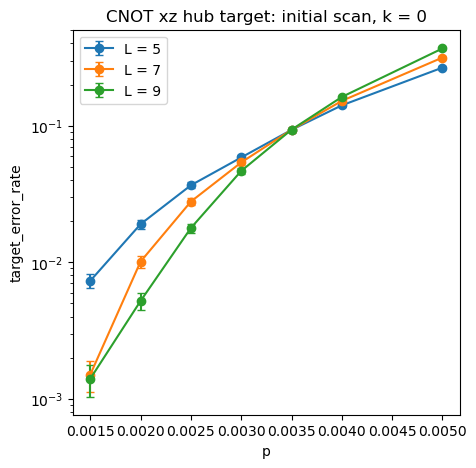

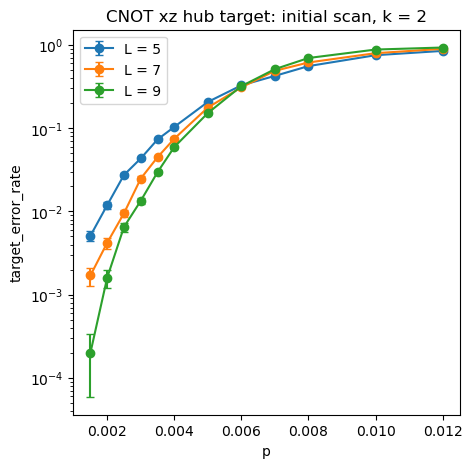

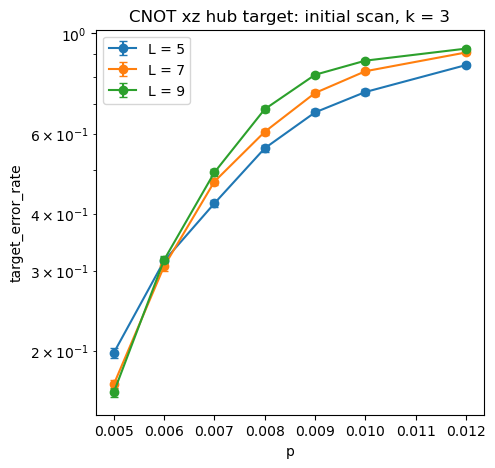

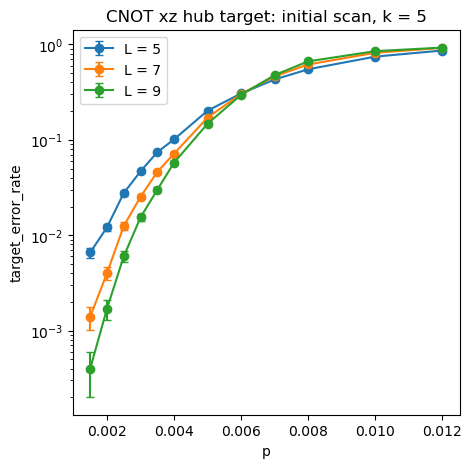

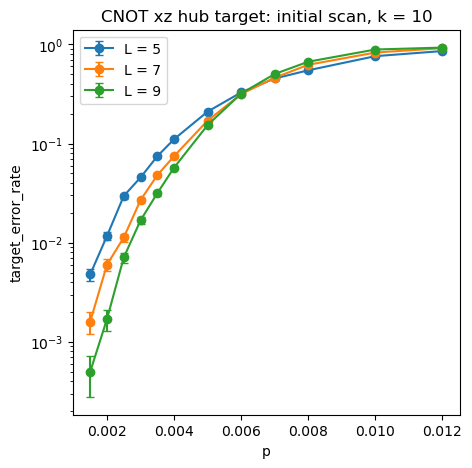

In [3]:
for gap, scan in initial_scans.items():
    plot_rate_scan(
        scan,
        rate_name="target",
        title=f"CNOT xz hub target: initial scan, k = {gap}",
        ylabel="target_error_rate",
    )

### Control error rate

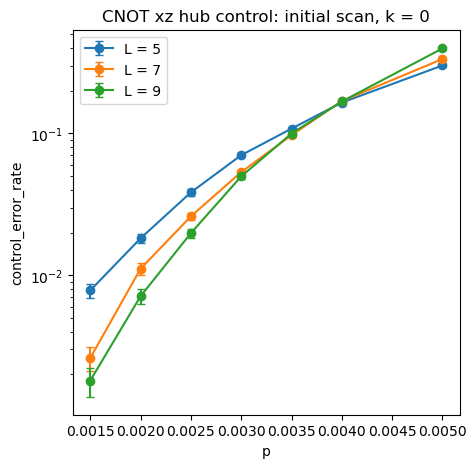

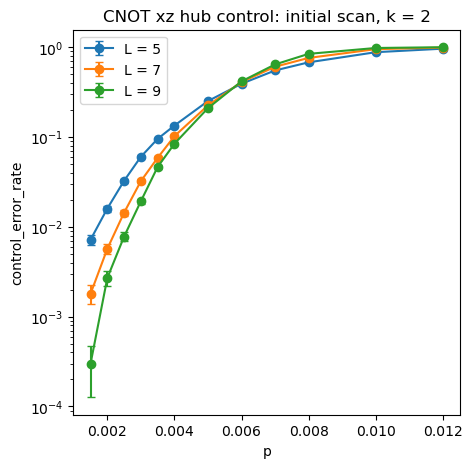

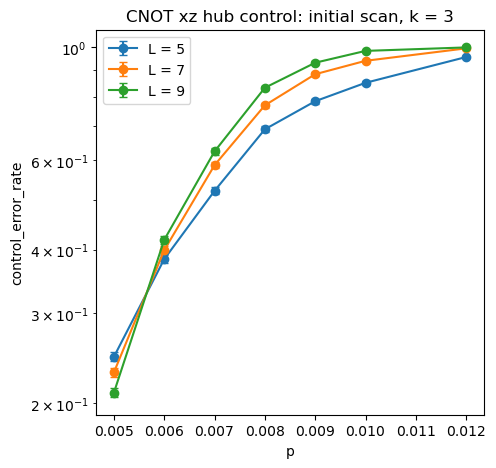

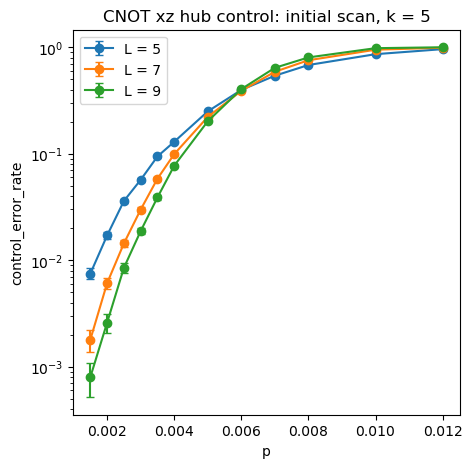

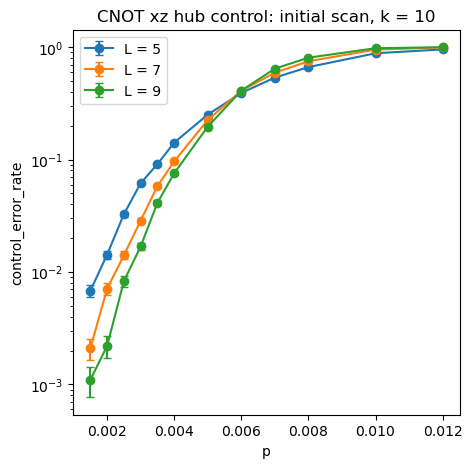

In [4]:
for gap, scan in initial_scans.items():
    plot_rate_scan(
        scan,
        rate_name="control",
        title=f"CNOT xz hub control: initial scan, k = {gap}",
        ylabel="control_error_rate",
    )

### Threshold estimates
Crossing of the target error rate for the two largest sizes and the full-scan `p` grid built around it (`hub_initial_scan_summary`). `L = 9` runs worse than its neighbours (memory full scan), so these crossings are probably low.

In [5]:
for gap in initial_scans:
    summary = hub_initial_scan_summary(DATA_DIR, gap, pattern=INITIAL_PATTERN)
    print(summary[summary.index("\np_c estimate") + 1:] if "\np_c estimate" in summary else summary.splitlines()[-1])
    print()

p_c estimate (L = 7/9): 0.349%
suggested full scan (11 values of p):
  GAP_ROUNDS=0 P_LIST="0.00175 0.00225 0.00275 0.003 0.00325 0.0035 0.00375 0.004 0.00425 0.0045 0.00525" bash jobs/cnot_primitive_xz_hub_full_scan.sh

p_c estimate (L = 7/9): 0.570%
suggested full scan (10 values of p):
  GAP_ROUNDS=2 P_LIST="0.003 0.0035 0.0045 0.005 0.0055 0.006 0.0065 0.007 0.0075 0.0085" bash jobs/cnot_primitive_xz_hub_full_scan.sh

p_c estimate (L = 7/9): 0.540%
suggested full scan (10 values of p):
  GAP_ROUNDS=3 P_LIST="0.0025 0.0035 0.004 0.0045 0.005 0.0055 0.006 0.0065 0.007 0.008" bash jobs/cnot_primitive_xz_hub_full_scan.sh

p_c estimate (L = 7/9): 0.630%
suggested full scan (10 values of p):
  GAP_ROUNDS=5 P_LIST="0.003 0.004 0.005 0.0055 0.006 0.0065 0.007 0.0075 0.008 0.0095" bash jobs/cnot_primitive_xz_hub_full_scan.sh

p_c estimate (L = 7/9): 0.581%
suggested full scan (10 values of p):
  GAP_ROUNDS=10 P_LIST="0.003 0.004 0.0045 0.005 0.0055 0.006 0.0065 0.007 0.0075 0.0085" bash job

## Full scan
Every gap with full-scan results at all sizes `L = 5-13` (`jobs/cnot_primitive_xz_hub_full_scan.sh`: `N = L` and `N = 2L`, `10^5` trials per point, split into `_rep<r>` files that are summed). So far only `k = 1`, from the local run (1500 failed trials or `10^4` trials per point); `k = 2, 5, 10` get the shared default grid of `k = 3`. The fit windows are set around each gap's initial-scan crossing; check them when new data arrive.

In [6]:
# Full scan
full_L_values = [5, 7, 9, 11, 13]
cnot_dirs = {"N = L": "NL", "N = 2L": "N2L"}


def full_scan_p_values(gap, n_dir):
    # p values with full-scan results at every size
    by_L = {}
    for path in (DATA_DIR / f"k_{gap}" / n_dir).glob(FULL_PATTERN):
        record = parse_result_file(path)
        by_L.setdefault(int(record["L"]), set()).add(round(record["p"], 6))
    return sorted(set.intersection(*[by_L.get(L, set()) for L in full_L_values]))


full_p_values = {}
full_scans = {}
for gap in (0, 1, 2, 3, 5, 10):
    for tag, n_dir in cnot_dirs.items():
        p_values = full_scan_p_values(gap, n_dir)
        if p_values:
            full_p_values[gap, tag] = p_values
            full_scans[gap, tag] = load_hub_scan(gap, n_dir, p_values, full_L_values, f"XZ hub k = {gap}, {tag} full scan")
            full_scans[gap, tag].print_summary()
            print()
full_gaps = sorted({gap for gap, _ in full_scans})
print("Gaps with full-scan data:", full_gaps)

# Select the exact p and L groups used by every fit (windows around each gap's initial-scan crossing).
fit_p_values = {
    0: [0.003, 0.00325, 0.0035, 0.00375, 0.004],
    1: [0.0045, 0.005, 0.0055, 0.006, 0.0065],
    2: [0.005, 0.0055, 0.006, 0.0065, 0.007],
    3: [0.005, 0.0055, 0.006, 0.0065, 0.007],
    5: [0.005, 0.0055, 0.006, 0.0065, 0.007],
    10: [0.005, 0.0055, 0.006, 0.0065, 0.007],
}
fit_L_values = [7, 9, 11, 13]
fit_degree = 2
full_fits = []

Loaded 50 requested XZ hub k = 1, N = L full scan files; ignored 0 files outside the requested lists
L values: [ 5  7  9 11 13]
p values: [0.003  0.004  0.0045 0.005  0.0055 0.006  0.0065 0.007  0.008  0.009 ]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]]

Loaded 50 requested XZ hub k = 1, N = 2L full scan files; ignored 0 files outside the requested lists
L values: [ 5  7  9 11 13]
p values: [0.003  0.004  0.0045 0.005  0.0055 0.006  0.0065 0.007  0.008  0.009 ]
repeat counts:
 [[1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]]

Gaps with full-scan data: [1]


### Target error rate

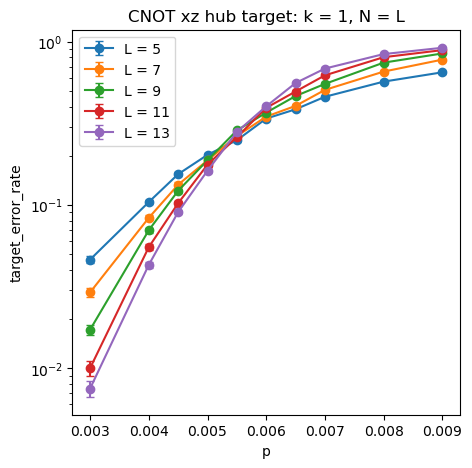

#### Finite-size scaling fit: XZ hub full scan — target, k = 1, N = L

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.004, 0.006]$ and $L \in [7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.00533(5) |
| $p_c$ (%) | 0.533(5) |
| $\nu$ | 1.3(1) |
| $A$ | 0.237(9) |
| $B$ | 31(4) |
| $C$ | 969(256) |
| $\chi^2 / \mathrm{dof}$ | 23.08 / 15 = 1.54 |
| goodness-of-fit $p$-value | 0.0824 |

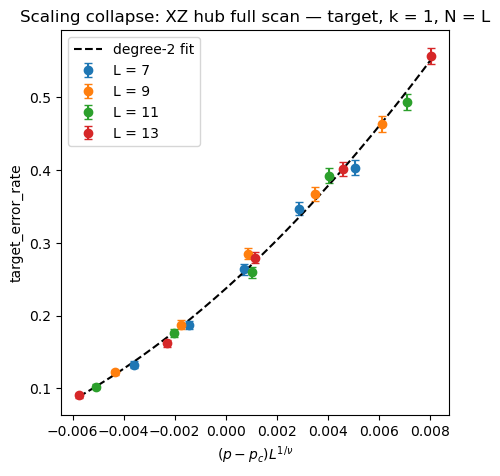

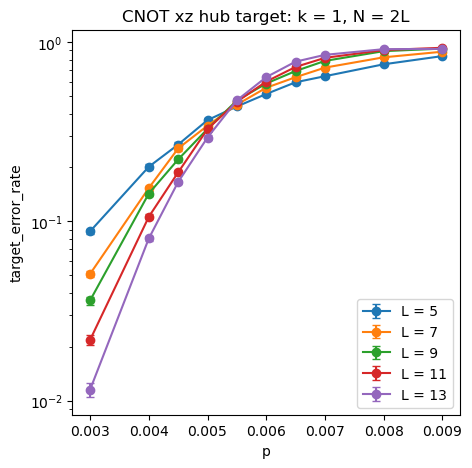

#### Finite-size scaling fit: XZ hub full scan — target, k = 1, N = 2L

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.004, 0.006]$ and $L \in [7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.00532(5) |
| $p_c$ (%) | 0.532(5) |
| $\nu$ | 1.37(9) |
| $A$ | 0.41(1) |
| $B$ | 47(6) |
| $C$ | 48(158) |
| $\chi^2 / \mathrm{dof}$ | 17.50 / 15 = 1.17 |
| goodness-of-fit $p$-value | 0.29 |

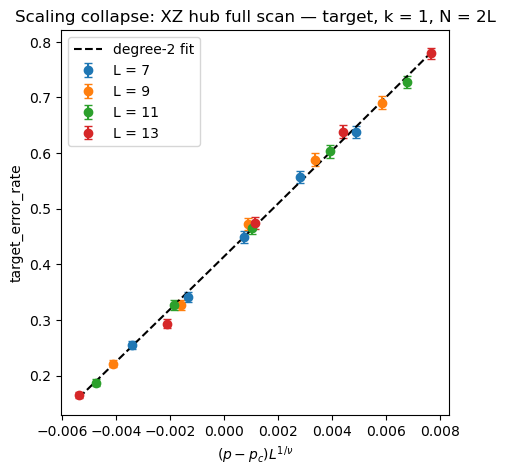

In [7]:
for (gap, tag), scan in full_scans.items():
    plot_rate_scan(
        scan,
        rate_name="target",
        title=f"CNOT xz hub target: k = {gap}, {tag}",
        ylabel="target_error_rate",
    )
    fit_scan = load_hub_scan(gap, cnot_dirs[tag], fit_p_values[gap], fit_L_values, f"XZ hub k = {gap}, {tag} target fit")
    fit = fit_finite_size_scaling(
        fit_scan,
        rate_name="target",
        label=f"XZ hub full scan — target, k = {gap}, {tag}",
        polynomial_degree=fit_degree,
        fit_p_range=(min(fit_p_values[gap]), max(fit_p_values[gap])),
        min_L=min(fit_L_values),
    )
    full_fits.append(fit)
    display_finite_size_scaling_fit(fit, "target_error_rate")

### Control error rate

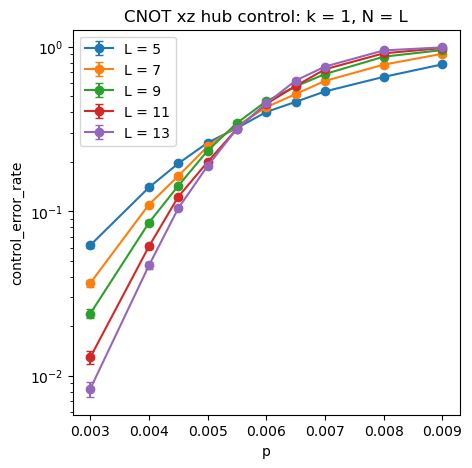

#### Finite-size scaling fit: XZ hub full scan — control, k = 1, N = L

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.004, 0.006]$ and $L \in [7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.00571(6) |
| $p_c$ (%) | 0.571(6) |
| $\nu$ | 1.7(1) |
| $A$ | 0.37(2) |
| $B$ | 63(7) |
| $C$ | 2324(505) |
| $\chi^2 / \mathrm{dof}$ | 30.72 / 15 = 2.05 |
| goodness-of-fit $p$-value | 0.00956 |

> **Fit-quality warning:** the degree-2 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

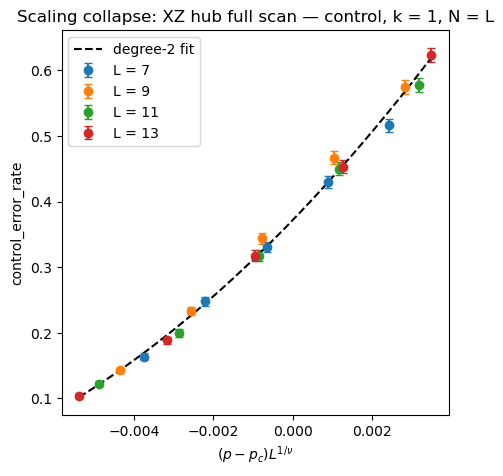

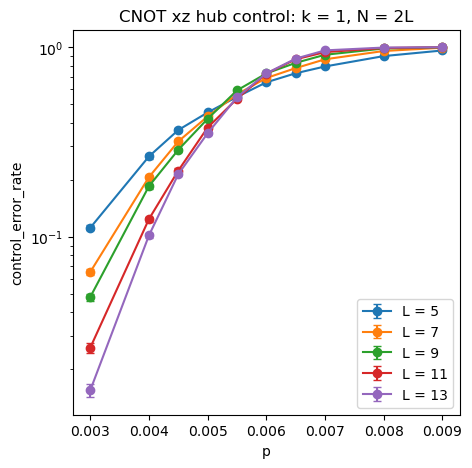

#### Finite-size scaling fit: XZ hub full scan — control, k = 1, N = 2L

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.004, 0.006]$ and $L \in [7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.00567(6) |
| $p_c$ (%) | 0.567(6) |
| $\nu$ | 1.8(1) |
| $A$ | 0.60(2) |
| $B$ | 80(8) |
| $C$ | -323(352) |
| $\chi^2 / \mathrm{dof}$ | 61.86 / 15 = 4.12 |
| goodness-of-fit $p$-value | 1.21e-07 |

> **Fit-quality warning:** the degree-2 scaling model is rejected at the 5% level for this window. The covariance errors are statistical only; vary the degree, fit window, and minimum $L$ before quoting a final uncertainty.

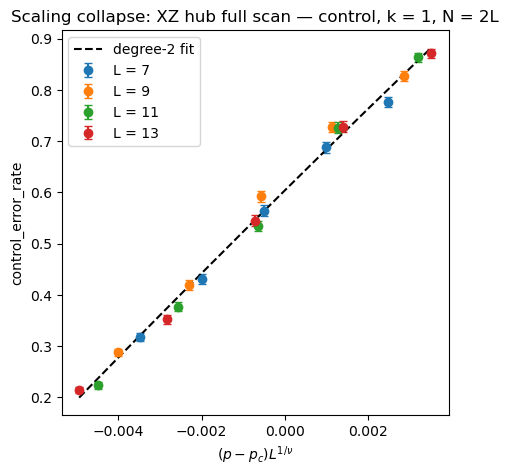

In [8]:
for (gap, tag), scan in full_scans.items():
    plot_rate_scan(
        scan,
        rate_name="control",
        title=f"CNOT xz hub control: k = {gap}, {tag}",
        ylabel="control_error_rate",
    )
    fit_scan = load_hub_scan(gap, cnot_dirs[tag], fit_p_values[gap], fit_L_values, f"XZ hub k = {gap}, {tag} control fit")
    fit = fit_finite_size_scaling(
        fit_scan,
        rate_name="control",
        label=f"XZ hub full scan — control, k = {gap}, {tag}",
        polynomial_degree=fit_degree,
        fit_p_range=(min(fit_p_values[gap]), max(fit_p_values[gap])),
        min_L=min(fit_L_values),
    )
    full_fits.append(fit)
    display_finite_size_scaling_fit(fit, "control_error_rate")

### Target error rate per CNOT
`eps = P_max [1 - (1 - P / P_max)^(1/N)]` at `N = L` (`P_max = 15/16`), and `Lambda` from `ln eps` against `(L + 1)/2`.

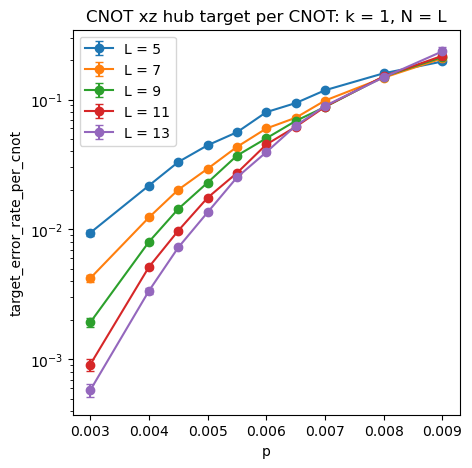

k = 1, p = 0.0030: Lambda = 2.09 ± 0.05
k = 1, p = 0.0040: Lambda = 1.59 ± 0.02
k = 1, p = 0.0045: Lambda = 1.46 ± 0.02
k = 1, p = 0.0050: Lambda = 1.34 ± 0.01
k = 1, p = 0.0055: Lambda = 1.23 ± 0.01
k = 1, p = 0.0060: Lambda = 1.19 ± 0.01


In [9]:
for gap in full_gaps:
    scan = full_scans[gap, "N = L"]
    target = scan.rate("target")
    eps = np.full_like(target.values, np.nan)
    eps_err = np.full_like(target.values, np.nan)
    for i, L in enumerate(scan.L_values):
        for j in range(len(scan.p_values)):
            trials = scan.trials[i, j]
            if 0 < target.values[i, j] < P_MAX_BLOCK:
                eps[i, j], eps_err[i, j] = single_point_rate(target.values[i, j] * trials, trials, L, p_max=P_MAX_BLOCK)
    per_cnot = rates_as_scan({"target": RateEstimate(eps, eps_err)}, L_values=scan.L_values, p_values=scan.p_values, label="per CNOT")
    plot_rate_scan(
        per_cnot,
        rate_name="target",
        title=f"CNOT xz hub target per CNOT: k = {gap}, N = L",
        ylabel="target_error_rate_per_cnot",
    )
    # Lambda up to the fourth p of the fit window (0.6% for k = 1)
    for j, p in enumerate(scan.p_values):
        if p <= fit_p_values[gap][3]:
            lam = fit_lambda(scan.L_values, eps[:, j], eps_err[:, j])
            print(f"k = {gap}, p = {p:.4f}: Lambda = {lam.Lambda:.2f} ± {lam.Lambda_error:.2f}")

### Control error rate by partner index
Final failures of partner `j`, pooled over `p` and divided by their mean over partners. Partner `j` carries the hub's Z errors made before gate `j`, so the final rate grows with `j`; its own faults (frame snapshots) do not.

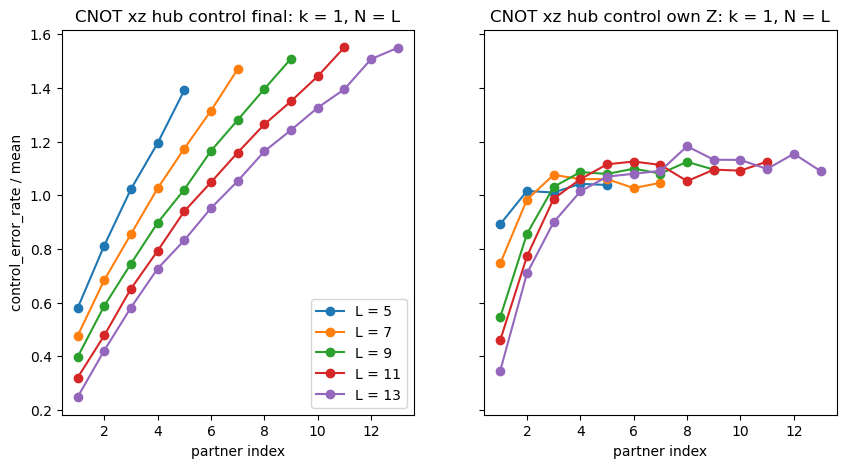

In [10]:
profile_keys = {"final": "partner_failures_by_index", "own Z": "partner_z_own_failures_by_index"}
for gap in full_gaps:
    _, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
    for ax, (tag, key) in zip(axes, profile_keys.items()):
        for L in full_L_values:
            counts = 0
            for path in (DATA_DIR / f"k_{gap}" / "NL").glob(FULL_PATTERN):
                record = parse_result_file(path)
                if int(record["L"]) == L and round(record["p"], 6) in full_p_values[gap, "N = L"]:
                    counts = counts + np.asarray(record[key], dtype=float)
            ax.plot(np.arange(1, L + 1), counts / counts.mean(), "o-", label=f"L = {L}")
        ax.set_xlabel("partner index")
        ax.set_title(f"CNOT xz hub control {tag}: k = {gap}, N = L")
    axes[0].set_ylabel("control_error_rate / mean")
    axes[0].legend()
    plt.show()

In [11]:
display_fit_summary(
    full_fits,
    title="XZ hub full-scan fit summary",
)

## XZ hub full-scan fit summary

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| XZ hub full scan — target, k = 1, N = L | 2 | 0.00533(5) | 0.533(5) | 1.3(1) | 1.54 | 0.0824 |
| XZ hub full scan — target, k = 1, N = 2L | 2 | 0.00532(5) | 0.532(5) | 1.37(9) | 1.17 | 0.29 |
| XZ hub full scan — control, k = 1, N = L | 2 | 0.00571(6) | 0.571(6) | 1.7(1) | 2.05 | 0.00956 |
| XZ hub full scan — control, k = 1, N = 2L | 2 | 0.00567(6) | 0.567(6) | 1.8(1) | 4.12 | 1.21e-07 |